### Handling Categorical Data in Feature Engineering

#### 1. What are categorical features?
- Data that can be categorized but lacks an inherent hierarchy or order is known as categorical data. In other words, there is no mathematical connection between the categories.
- If you try and train ML or most SKlearn models with categorical data, you’ll immediately get an error.
- Before categorical data can be utilized as input to a machine learning model, it must first be transformed into numerical data.
- This process of converting categorical data into numeric representation is known as encoding.

Examples:
- Gender → {Male, Female}
- City → {Delhi, Mumbai, Kolkata}
- PropertyType → {Apartment, House, Studio}

#### 2. Two main types
- **Nominal (unordered)** — no natural order.
    - Example: Color = {Red, Blue, Green}
- **Ordinal (ordered)** — categories have a meaningful order but differences are not numeric.
    - Example: Satisfaction = {Poor < Average < Good < Excellent}
    - Levels of education = {high school, bachelor's, master's}

In [23]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)
n = 50

df = pd.DataFrame({
    # Nominal
    'Gender': np.random.choice(['Male', 'Female', 'Other'], n),
    'Color': np.random.choice(['Red', 'Blue', 'Green', 'Yellow'], n),
    
    # Ordinal
    'Education': np.random.choice(['High School', 'Bachelors', 'Masters', 'PhD'], n),
    'Satisfaction': np.random.choice(['Low', 'Medium', 'High'], n),
    
    # Binary
    'HasCar': np.random.choice([0, 1], n),
    
    # High Cardinality
    'City': np.random.choice([f'City_{i}' for i in range(1, 11)], n)
})

df.head()

,Gender,Color,Education,Satisfaction,HasCar,City
0,Other,Blue,High School,Low,1,City_7
1,Male,Red,Bachelors,High,1,City_2
2,Other,Blue,Masters,Medium,1,City_3
3,Other,Red,High School,High,1,City_1
4,Male,Blue,PhD,High,1,City_5


#### 3. How to tell if a column is categorical (step-by-step)
- Inspect the data type (in pandas: df[col].dtype) — often object or category.
- Check unique value count: df[col].nunique(). Few unique values → likely categorical.
- Ask: Are the values labels or measured quantities?
    - If labels/codes → categorical.
    - If counts/measurements where arithmetic makes sense → numeric

In [24]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Gender        50 non-null     str  
 1   Color         50 non-null     str  
 2   Education     50 non-null     str  
 3   Satisfaction  50 non-null     str  
 4   HasCar        50 non-null     int64
 5   City          50 non-null     str  
dtypes: int64(1), str(5)
memory usage: 2.5 KB


In [25]:
df["Education"].value_counts()

Education
High School    17
PhD            14
Masters        13
Bachelors       6
Name: count, dtype: int64

In [26]:
df.nunique()

Gender           3
Color            4
Education        4
Satisfaction     3
HasCar           2
City            10
dtype: int64

#### 4. EDA & visualization (quick steps)
- Frequency table: df[col].value_counts()
- Relative frequency: df[col].value_counts(normalize=True)
- Bar plot: df[col].value_counts().plot(kind='bar')
- Cross-tab with target: pd.crosstab(df[col], df['target'], normalize='index')


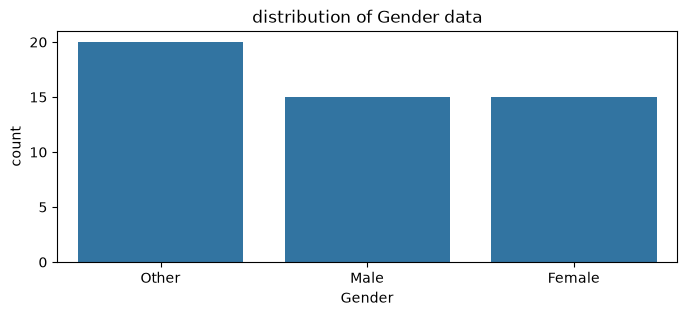

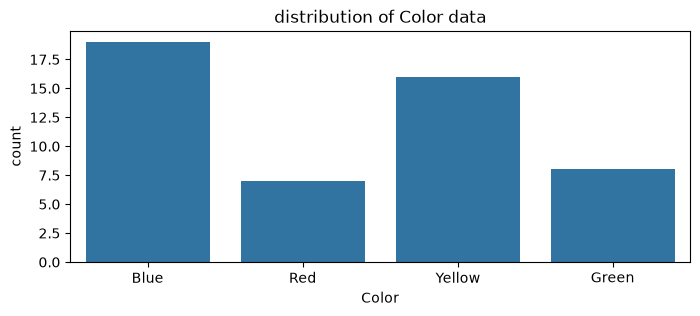

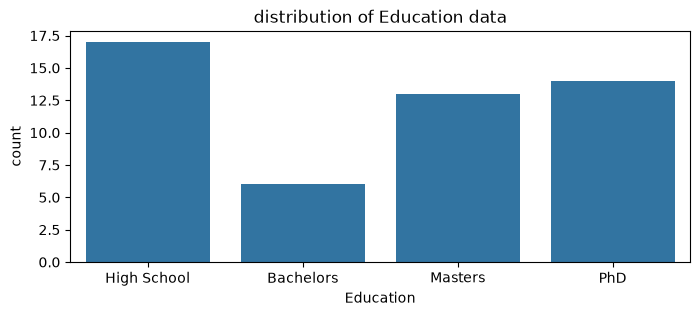

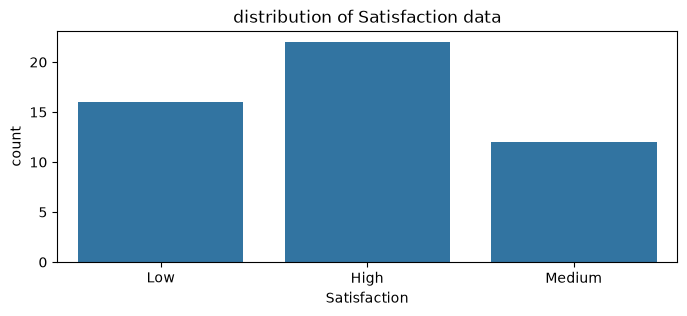

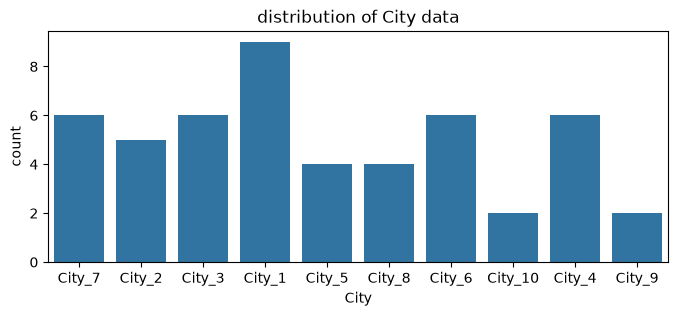

In [27]:
cat_cols = df.select_dtypes(include='str').columns
for label in cat_cols:
    plt.figure(figsize=(8,3))
    sns.countplot(x=label, data=df)
    plt.title(f"distribution of {label} data")
    plt.show()

#### 5. Common encodings (how to convert to numbers for ML)
- One-Hot Encoding — binary column per category. Good for low-cardinality nominal features.
- Label Encoding — integer labels (be careful: introduces an order).
- Ordinal Encoding — map categories to integers with a meaningful order.
- Frequency / Count Encoding — replace category by its frequency/count.
- Target Encoding (mean encoding) — replace category by mean(target) — risk of leakage; use CV.

In [28]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder

In [29]:
print(cat_cols)

Index(['Gender', 'Color', 'Education', 'Satisfaction', 'City'], dtype='str')


**1. Labale encoding**

In [30]:
le = LabelEncoder()
df["Education_label_encoder"] = le.fit_transform(df["Education"])
df["Satisfaction_label_encoder"] = le.fit_transform(df["Satisfaction"])

In [31]:
df.head()

,Gender,Color,Education,Satisfaction,HasCar,City,Education_label_encoder,Satisfaction_label_encoder
0,Other,Blue,High School,Low,1,City_7,1,1
1,Male,Red,Bachelors,High,1,City_2,0,0
2,Other,Blue,Masters,Medium,1,City_3,2,2
3,Other,Red,High School,High,1,City_1,1,0
4,Male,Blue,PhD,High,1,City_5,3,0


In [32]:
df["Education"].value_counts()

Education
High School    17
PhD            14
Masters        13
Bachelors       6
Name: count, dtype: int64

**2. Ordinal Encoding**

In [33]:
ordinal_cols = ["Education","Satisfaction"]

# define the order for ordinal features
education_order = ["High School","Bachelors","Masters","PhD"]
satisfication_order = ['Low',"Medium", "High"]

ordinal_encoder = OrdinalEncoder(categories=[education_order, satisfication_order])
ordinal_encoded = ordinal_encoder.fit_transform(df[ordinal_cols])
df_ordina_encoder = pd.DataFrame(ordinal_encoded, columns=[f"{c}_enocoded" for c in ordinal_cols])

In [34]:
df_ordina_encoder.head()

,Education_enocoded,Satisfaction_enocoded
0,0.0,0.0
1,1.0,2.0
2,2.0,1.0
3,0.0,2.0
4,3.0,2.0
